# Atelier 5.B — Transposition à votre organisation

**Durée : 40 min** · Préparation de la restitution

Vous repartez d'un des processus identifiés dans le questionnaire de positionnement. En 40 minutes, vous allez :

1. l'évaluer avec une **grille d'éligibilité** et le placer dans une **matrice de priorisation** ;
2. passer de sa **description métier** à une **spécification** (étapes, décisions, données, exceptions) ;
3. ébaucher son **business case**, coûts cachés compris ;
4. établir un **pré-diagnostic réglementaire** (AI Act, nLPD).

Décrivez votre processus de façon **anonymisée** : ni nom de client, ni donnée personnelle, ni chiffre confidentiel. Les fonctions de calcul sont dans `business_case.py` ; le canevas `5B_canevas_processus.md` reprend les mêmes rubriques sur papier.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Markdown, display
from pydantic import BaseModel, Field

import business_case as bc
import outils_llm as llm

MODELE = llm.choisir_modele()
print("Modèle :", MODELE)

Modèle : groq:openai/gpt-oss-120b


## 1. La grille d'éligibilité

Six critères notés de 1 (défavorable) à 5 (favorable), pondérés. Au-dessus de 3,5, le processus est un bon candidat ; en dessous de 2,5, il vaut mieux chercher ailleurs.

In [2]:
pd.DataFrame([{"critère": c, "poids": p, "question": q, "repères": r} for c, (p, q, r) in bc.CRITERES.items()]).set_index("critère")

,poids,question,repères
critère,,,
volume,0.20,Combien de cas par mois ?,1 : moins de 50 ; 3 : environ 500 ; 5 : plus d...
repetitivite,0.15,Les cas se ressemblent-ils ?,1 : chaque cas est unique ; 5 : quelques varia...
structuration,0.15,Les données d'entrée sont-elles structurées ?,"1 : textes libres, scans ; 5 : formulaires, ba..."
regles,0.15,Les règles de décision sont-elles explicites e...,1 : jugement d'expert ; 5 : règles écrites
valeur,0.20,Quel gain attendu ?,"temps, délai de réponse, qualité, conformité, ..."
risque,0.15,Une erreur est-elle grave ?,1 : atteinte aux personnes ou aux droits ; 5 :...


## 2. Un portefeuille d'exemples

Sept processus d'une entreprise comme Fictiva. L'**effort** (1 à 5) estime la difficulté d'automatisation : intégrations, qualité des données, conduite du changement.

In [3]:
portefeuille = bc.portefeuille(bc.charger_processus())
portefeuille

,processus,domaine,eligibilite,effort,risque,typologie,quadrant
id,,,,,,,
P2,Saisie des factures fournisseurs,Comptabilité,4.35,2,4,traitement intelligent de documents (IDP),gain rapide
P3,Rapprochement bancaire,Finance,4.10,1,3,rapprochement,gain rapide
P1,Traitement des emails clients,Service client,3.90,3,4,support,gain rapide
P5,Reporting mensuel des ventes,Direction,3.15,2,4,reporting,à reconsidérer
P4,Onboarding des nouveaux clients B2B,Ventes,3.10,3,3,onboarding,à reconsidérer
P6,Présélection des candidatures,Ressources humaines,2.40,4,1,décision sur des personnes (haut risque selon ...,à écarter
P7,Négociation des contrats-cadres,Achats,1.75,5,2,"décision stratégique, peu répétitive",à écarter


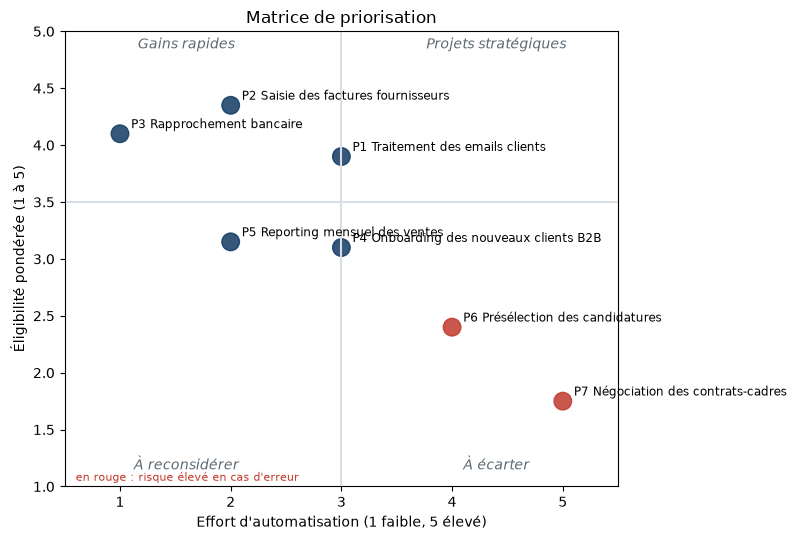

In [4]:
fig = bc.matrice_priorisation(portefeuille)

**À discuter.**

- Le rapprochement bancaire et la saisie des factures sont des **gains rapides** : données structurées, règles claires, forts volumes. Une RPA classique ou un outil de traitement de documents (IDP) suffit souvent : l'IA générative n'est pas toujours nécessaire.
- Le traitement des emails clients exige de comprendre du texte libre : c'est le terrain de la **RPA 2.0**.
- La présélection des candidatures touche des personnes : c'est un système **à haut risque** au sens de l'AI Act. Même techniquement faisable, elle demande une gouvernance lourde (section 5).

## 3. De la description métier à la spécification

Le métier décrit un processus en quelques phrases ; l'équipe technique a besoin d'étapes, d'acteurs, de systèmes, de points de décision et d'exceptions. Un LLM produit un **premier jet** de spécification, que le métier relit et corrige ; un outil de *process mining* l'aurait confronté aux traces réelles du système.

In [5]:
class Etape(BaseModel):
    acteur: str = Field(description="Qui agit : un rôle, jamais une personne nommée")
    action: str
    systeme: str = Field(description="Outil ou système utilisé (email, ERP, CRM, tableur…)")
    automatisable: str = Field(description="oui, partiellement ou non, avec une justification courte")

class Specification(BaseModel):
    objectif: str
    declencheur: str
    etapes: list[Etape]
    decisions: list[str] = Field(description="Points de décision et règles appliquées")
    exceptions: list[str] = Field(description="Cas qui sortent du chemin nominal")
    donnees_personnelles: list[str] = Field(description="Catégories de données personnelles traitées")
    indicateurs: list[str] = Field(description="Indicateurs pour mesurer le processus")

PROMPT_SPEC = """Tu es analyste de processus. À partir de la description métier, produis une spécification
structurée du processus actuel (avant automatisation). N'invente aucun système ni aucune règle absents de la
description : écris « à préciser » quand une information manque."""

DESCRIPTION = """Le service client reçoit environ 300 emails par jour. Un collaborateur lit chaque email, identifie
le client et sa commande dans le CRM, puis classe la demande : réclamation, remboursement, litige de facturation,
question sur un produit ou autre. Pour un remboursement, il applique la politique de retours (délais, frais de
traitement, exclusions) et calcule le montant dans un tableur ; au-delà de 5 000 CHF, le responsable doit valider.
Les litiges de facturation sont transmis à la comptabilité. Il rédige ensuite la réponse au client et crée un
ticket dans le CRM. Les demandes urgentes (activité du client à l'arrêt, problème de sécurité) sont traitées en
priorité. Le délai de réponse visé est de deux jours ouvrables."""

specification = llm.demander(DESCRIPTION, systeme=PROMPT_SPEC, modele=MODELE, schema=Specification).objet
print("Objectif   :", specification.objectif)
print("Déclencheur:", specification.declencheur)
display(pd.DataFrame([e.model_dump() for e in specification.etapes]))
for titre, liste in [("Décisions", specification.decisions), ("Exceptions", specification.exceptions),
                     ("Données personnelles", specification.donnees_personnelles), ("Indicateurs", specification.indicateurs)]:
    print(f"\n{titre} :\n  - " + "\n  - ".join(liste))

Objectif   : Traiter les emails du service client et répondre aux demandes (réclamations, remboursements, litiges, questions) dans un délai de deux jours ouvrables.
Déclencheur: Réception d'un email client dans la boîte de réception du service client.


,acteur,action,systeme,automatisable
0,Collaborateur du service client,Lire l'email reçu,Email (boîte de réception),"Oui, partiellement - la lecture peut être assi..."
1,Collaborateur du service client,Rechercher le client et la commande dans le CRM,CRM,"Oui, partiellement - la recherche peut être au..."
2,Collaborateur du service client,"Classer la demande (réclamation, remboursement...",CRM,"Oui, partiellement - classification assistée p..."
3,Collaborateur du service client,Appliquer la politique de retours et calculer ...,Tableur,"Oui, partiellement - les règles de calcul peuv..."
4,Responsable du service client,Valider le remboursement lorsque le montant dé...,Email ou CRM (à préciser),Non - décision financière nécessitant une vali...
5,Collaborateur du service client,Transmettre le litige de facturation à la comp...,CRM ou Email,"Oui, partiellement - l'envoi peut être automat..."
6,Collaborateur du service client,Rédiger la réponse au client,Email,"Oui, partiellement - modèles de réponse dispon..."
7,Collaborateur du service client,Créer un ticket dans le CRM pour suivre la dem...,CRM,Oui



Décisions :
  - Classification du type de demande selon le contenu de l'email
  - Si le montant du remboursement > 5 000 CHF alors validation par le responsable
  - Si la demande est urgente (client à l'arrêt ou problème de sécurité) alors traitement prioritaire
  - Respect du délai de réponse de 2 jours ouvrables

Exceptions :
  - Demande urgente traitée en priorité hors du flux standard
  - Client non identifié dans le CRM – recherche manuelle supplémentaire
  - Remboursement exclu par la politique de retours (ex. produit endommagé)

Données personnelles :
  - Identité du client (nom, prénom, coordonnées)
  - Détails de la commande (numéro, articles, dates)
  - Informations de facturation / paiement

Indicateurs :
  - Nombre d'emails traités par jour
  - Taux de réponses envoyées dans les 2 jours ouvrables
  - Temps moyen de traitement d'une demande
  - Pourcentage de remboursements >5 000 CHF nécessitant validation
  - Nombre de litiges transmis à la comptabilité


In [6]:
# Le même processus en diagramme (rendu par JupyterLab)
def diagramme(spec: Specification) -> str:
    propre = lambda texte: texte.replace('"', "'")
    noeuds = [f'  E{i}["{propre(e.acteur)} : {propre(e.action[:45])}"]' for i, e in enumerate(spec.etapes)]
    liens = [f"  E{i} --> E{i + 1}" for i in range(len(spec.etapes) - 1)]
    return "```mermaid\nflowchart TD\n" + "\n".join(noeuds + liens).replace("(", " ").replace(")", " ") + "\n```"

display(Markdown(diagramme(specification)))

```mermaid
flowchart TD
  E0["Collaborateur du service client : Lire l'email reçu"]
  E1["Collaborateur du service client : Rechercher le client et la commande dans le C"]
  E2["Collaborateur du service client : Classer la demande  réclamation, remboursemen"]
  E3["Collaborateur du service client : Appliquer la politique de retours et calculer"]
  E4["Responsable du service client : Valider le remboursement lorsque le montant d"]
  E5["Collaborateur du service client : Transmettre le litige de facturation à la com"]
  E6["Collaborateur du service client : Rédiger la réponse au client"]
  E7["Collaborateur du service client : Créer un ticket dans le CRM pour suivre la de"]
  E0 --> E1
  E1 --> E2
  E2 --> E3
  E3 --> E4
  E4 --> E5
  E5 --> E6
  E6 --> E7
```

✏️ Relisez la spécification : qu'a-t-elle mal compris ? Qu'a-t-elle omis ? C'est le travail de l'analyste métier, que le LLM accélère sans le remplacer.

## 4. Le business case

Les hypothèses par défaut correspondent au traitement des emails de Fictiva ; le taux d'automatisation et la consommation de tokens reprennent, s'ils existent, les indicateurs mesurés dans l'atelier 5.A.

In [7]:
hypotheses = bc.Hypotheses()
mesures = Path("resultats/indicateurs_5A.json")
if mesures.exists():
    kpi = json.loads(mesures.read_text(encoding="utf-8"))
    hypotheses.taux_automatisation = kpi["taux_automatisation_bout_en_bout"] or hypotheses.taux_automatisation
    hypotheses.taux_validation = max(0.0, round(1 - hypotheses.taux_automatisation - 0.15, 2))
    hypotheses.tokens_par_cas = kpi["tokens_par_dossier"] or hypotheses.tokens_par_cas
    print("Hypothèses reprises de l'atelier 5.A :", {"taux_automatisation": hypotheses.taux_automatisation,
                                                    "tokens_par_cas": hypotheses.tokens_par_cas})
pd.Series(bc.hypotheses_dict(hypotheses), name="hypothèse").to_frame()

Hypothèses reprises de l'atelier 5.A : {'taux_automatisation': 0.5, 'tokens_par_cas': 3258}


,hypothèse
cas_par_mois,6000.000
minutes_manuelles_par_cas,6.000
cout_horaire_chf,75.000
taux_automatisation,0.500
taux_validation,0.350
minutes_validation_par_cas,2.000
part_controle_qualite,0.050
taux_erreur_residuel,0.005
cout_par_erreur_chf,150.000
tokens_par_cas,3258.000


In [8]:
bilan = bc.business_case(hypotheses)
pd.Series(bilan, name="valeur").to_frame()

,valeur
heures_avant,7200.00
heures_apres,1980.00
gain_annuel_chf,391500.00
cout_llm_annuel_chf,56.00
cout_erreurs_annuel_chf,27000.00
couts_recurrents_annuels_chf,82056.00
benefice_net_annuel_chf,309444.00
benefice_premiere_annee_chf,229444.00
roi_premiere_annee,1.42
delai_retour_mois,3.10


**À observer.** Les tokens coûtent presque rien face à la **supervision humaine**, à l'**évaluation continue** (golden set, mises à jour des modèles et des prompts), à l'**exploitation** et aux **erreurs résiduelles**. Un business case qui ne compte que les tokens est faux.

Deux hypothèses pèsent le plus : le **volume** et le **taux d'automatisation**.

,gain_annuel_chf,couts_recurrents_annuels_chf,benefice_net_annuel_chf,delai_retour_mois
cas_par_mois,,,,
200,13050,55902,-42852,NaN
500,32625,57255,-24630,NaN
1000,65250,59509,5741,167.2
2000,130500,64019,66481,14.4
4000,261000,73038,187962,5.1
6000,391500,82056,309444,3.1
10000,652500,100094,552406,1.7


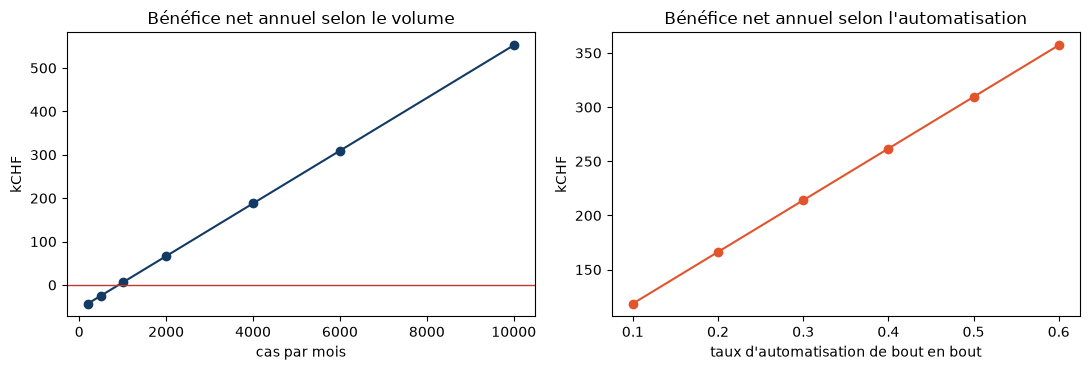

In [9]:
import matplotlib.pyplot as plt

volumes = bc.sensibilite(hypotheses, "cas_par_mois", [200, 500, 1000, 2000, 4000, 6000, 10000])
automatisation = bc.sensibilite(hypotheses, "taux_automatisation", [0.1, 0.2, 0.3, 0.4, 0.5, 0.6])
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(volumes.index, volumes.benefice_net_annuel_chf / 1000, marker="o", color="#123a63")
axes[0].axhline(0, color="#c0392b", lw=1)
axes[0].set(title="Bénéfice net annuel selon le volume", xlabel="cas par mois", ylabel="kCHF")
axes[1].plot(automatisation.index, automatisation.benefice_net_annuel_chf / 1000, marker="o", color="#e2542c")
axes[1].set(title="Bénéfice net annuel selon l'automatisation", xlabel="taux d'automatisation de bout en bout", ylabel="kCHF")
fig.tight_layout()
volumes

En dessous de quelques centaines de cas par mois, les coûts fixes (exploitation, évaluation, maintenance) l'emportent : le processus n'est pas rentable, même bien automatisé. Le seuil de rentabilité est le premier chiffre à présenter.

## 5. Pré-diagnostic réglementaire

Un questionnaire simplifié oriente la discussion avec le juriste et le délégué à la protection des données ; il ne remplace pas une analyse juridique. Calendrier de l'AI Act : pratiques interdites et obligation de maîtrise de l'IA depuis le 2 février 2025 ; obligations des systèmes à haut risque de l'annexe III à partir du 2 décembre 2027 (règlement 2026/1744).

In [10]:
for nom, diagnostic in [
    ("Traitement des emails clients", bc.risque_ai_act(interagit_avec_des_personnes=True, genere_du_contenu=True)),
    ("Présélection des candidatures", bc.risque_ai_act(domaines=("emploi",))),
    ("Rapprochement bancaire", bc.risque_ai_act()),
]:
    print(f"{nom} → {diagnostic['niveau']}")
    for obligation in diagnostic["obligations"]:
        print("   -", obligation)

Traitement des emails clients → risque limité : obligations de transparence (art. 50)
   - informer les personnes qu'elles échangent avec un système d'IA
   - signaler les contenus générés ou manipulés par l'IA
   - pour tous : maîtrise de l'IA des équipes (art. 4), en vigueur depuis le 2 février 2025
   - en Suisse : nLPD (transparence, droits des personnes, analyse d'impact si risque élevé)
Présélection des candidatures → haut risque (annexe III)
   - gestion des risques, qualité des données, documentation technique, journalisation
   - supervision humaine effective, exactitude et robustesse
   - applicable à partir du 2 décembre 2027 (règlement 2026/1744)
   - pour tous : maîtrise de l'IA des équipes (art. 4), en vigueur depuis le 2 février 2025
   - en Suisse : nLPD (transparence, droits des personnes, analyse d'impact si risque élevé)
Rapprochement bancaire → risque minimal
   - pas d'obligation spécifique ; codes de conduite volontaires
   - pour tous : maîtrise de l'IA des équip

## 6. À vous : votre processus

Remplacez l'exemple ci-dessous (traitement des notes de frais) par le processus identifié lors du positionnement, **anonymisé**, puis relancez les cellules suivantes.

In [11]:
MON_PROCESSUS = {
    "nom": "Contrôle des notes de frais",
    "description": """Chaque mois, environ 900 notes de frais arrivent par le portail RH avec leurs justificatifs
(photos de tickets, factures PDF). Un contrôleur vérifie les montants, la TVA, la conformité à la politique de
voyage, puis valide ou renvoie la note au collaborateur. Les notes de plus de 1 000 CHF sont validées par le
responsable financier. Le remboursement est versé avec le salaire.""",
    "notes": {"volume": 3, "repetitivite": 4, "structuration": 2, "regles": 4, "valeur": 3, "risque": 4},
    "effort": 3,
}
MES_HYPOTHESES = bc.Hypotheses(cas_par_mois=900, minutes_manuelles_par_cas=8, cout_horaire_chf=70,
                               taux_automatisation=0.4, taux_validation=0.4, construction_chf=50000,
                               exploitation_annuelle_chf=15000, evaluation_maintenance_annuelle_chf=15000)

In [12]:
eligibilite = bc.score_eligibilite(MON_PROCESSUS["notes"])
print(f"{MON_PROCESSUS['nom']} : éligibilité {eligibilite} / 5, effort {MON_PROCESSUS['effort']} → "
      f"{bc.quadrant(eligibilite, MON_PROCESSUS['effort'])}")

ma_specification = llm.demander(MON_PROCESSUS["description"], systeme=PROMPT_SPEC, modele=MODELE, schema=Specification).objet
display(pd.DataFrame([e.model_dump() for e in ma_specification.etapes]))
display(Markdown(diagramme(ma_specification)))
pd.Series(bc.business_case(MES_HYPOTHESES), name=MON_PROCESSUS["nom"]).to_frame()

Contrôle des notes de frais : éligibilité 3.3 / 5, effort 3 → à reconsidérer


,acteur,action,systeme,automatisable
0,Collaborateur,Soumettre la note de frais avec les justificat...,Portail RH,"Oui, déjà automatisé – la soumission se fait v..."
1,Contrôleur,"Vérifier les montants, la TVA et la conformité...",Portail RH / outil de contrôle (à préciser),Partiellement – les calculs peuvent être autom...
2,Contrôleur,Valider la note de frais ou la renvoyer au col...,Portail RH,Partiellement – la décision de validation rest...
3,Responsable financier,Valider les notes de frais dont le montant dép...,Portail RH / système de validation (à préciser),Non – décision financière requise
4,Service paie,Intégrer le remboursement dans le salaire mensuel,Système de paie / ERP (à préciser),Oui – le paiement est automatisé via le systèm...


```mermaid
flowchart TD
  E0["Collaborateur : Soumettre la note de frais avec les justifica"]
  E1["Contrôleur : Vérifier les montants, la TVA et la conformit"]
  E2["Contrôleur : Valider la note de frais ou la renvoyer au co"]
  E3["Responsable financier : Valider les notes de frais dont le montant dé"]
  E4["Service paie : Intégrer le remboursement dans le salaire men"]
  E0 --> E1
  E1 --> E2
  E2 --> E3
  E3 --> E4
```

,Contrôle des notes de frais
heures_avant,1440.00
heures_apres,439.00
gain_annuel_chf,70056.00
cout_llm_annuel_chf,9.00
cout_erreurs_annuel_chf,3240.00
couts_recurrents_annuels_chf,33249.00
benefice_net_annuel_chf,36807.00
benefice_premiere_annee_chf,-13193.00
roi_premiere_annee,-0.16
delai_retour_mois,16.30


## Préparer la restitution

Vous présenterez en **8 minutes**, suivies de 4 minutes d'échanges (grille : `../restitution/grille_restitution.md`) :

1. l'assistant de Fictiva industrialisé : démonstration, indicateurs de l'atelier 5.A, garde-fous ;
2. votre processus : place dans la matrice, spécification, business case et seuil de rentabilité ;
3. les risques et la gouvernance : niveau AI Act, données personnelles, rôle de l'humain ;
4. les trois premières actions de votre feuille de route à 90 jours (`../cloture/plan_action_90_jours.md`).